# generateur de donnees de series temporelles avec differents types shift et differents niveaux d'intensite

différents shifts:

un decalage de niveau (offset)

un changement d'echelle ou d'amplitude

une derive de tendance

un changement de saisonnalite

un changement du niveau de bruit

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from series_utils import generate_series

## Generation d'une serie temporelle

ça génére une série temporelle avec : une tendance lineaire, une composante saisonniere sinusoidale, et un bruit blanc gaussien.

## Visualisation

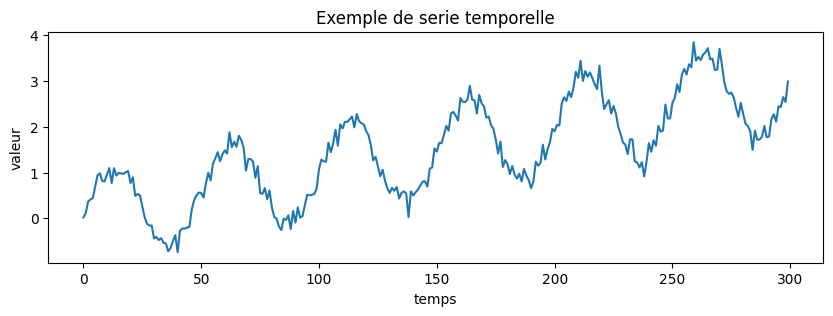

In [2]:
rng_demo = np.random.default_rng(0)
t_demo, series_demo = generate_series(300, trend_slope=0.01, seasonal_amplitude=1.0, seasonal_period=50, noise_std=0.15, rng=rng_demo)

plt.figure(figsize=(10, 3))
plt.plot(t_demo, series_demo)
plt.title("Exemple de serie temporelle")
plt.xlabel("temps")
plt.ylabel("valeur")
plt.show()

## Passage au format supervise par fenetre glissante

In [3]:
def sliding_window(series, window_size):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i:i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

## Construction d'une paire de domaines source et cible

In [4]:
def make_domain_pair(source_params, shift_type, intensity, n_points=800, window_size=20, seed=0):
    rng_source = np.random.default_rng(seed)
    rng_target = np.random.default_rng(seed + 1000)

    target_params = dict(source_params)
    offset = 0.0

    if shift_type == "offset":
        offset = intensity
    elif shift_type == "scale":
        target_params["seasonal_amplitude"] = source_params["seasonal_amplitude"] * (1 + intensity)
    elif shift_type == "trend":
        target_params["trend_slope"] = source_params["trend_slope"] * (1 + intensity)
    elif shift_type == "frequency":
        target_params["seasonal_period"] = source_params["seasonal_period"] / (1 + intensity)
    elif shift_type == "noise":
        target_params["noise_std"] = source_params["noise_std"] * (1 + intensity)
    else:
        raise ValueError(f"type de shift inconnu : {shift_type}")

    t_source, series_source = generate_series(n_points, rng=rng_source, **source_params)
    t_target, series_target = generate_series(n_points, rng=rng_target, **target_params)
    series_target = series_target + offset

    Xs, ys = sliding_window(series_source, window_size)
    Xt, yt = sliding_window(series_target, window_size)

    return dict(
        t_source=t_source, series_source=series_source, Xs=Xs, ys=ys,
        t_target=t_target, series_target=series_target, Xt=Xt, yt=yt,
        shift_type=shift_type, intensity=intensity,
    )


source_params = dict(
    trend_slope=0.01,
    seasonal_amplitude=1.0,
    seasonal_period=50,
    noise_std=0.15,
)

## Affichage

In [5]:
def plot_domain_pair(pair, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(pair["t_source"], pair["series_source"], label="domaine source")
    axes[0].plot(pair["t_target"], pair["series_target"], label="domaine cible")
    axes[0].set_title(title)
    axes[0].set_xlabel("temps")
    axes[0].legend()

    axes[1].hist(pair["series_source"], bins=30, alpha=0.5, label="domaine source")
    axes[1].hist(pair["series_target"], bins=30, alpha=0.5, label="domaine cible")
    axes[1].set_title("Distribution des valeurs")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## Shift 1 : offset

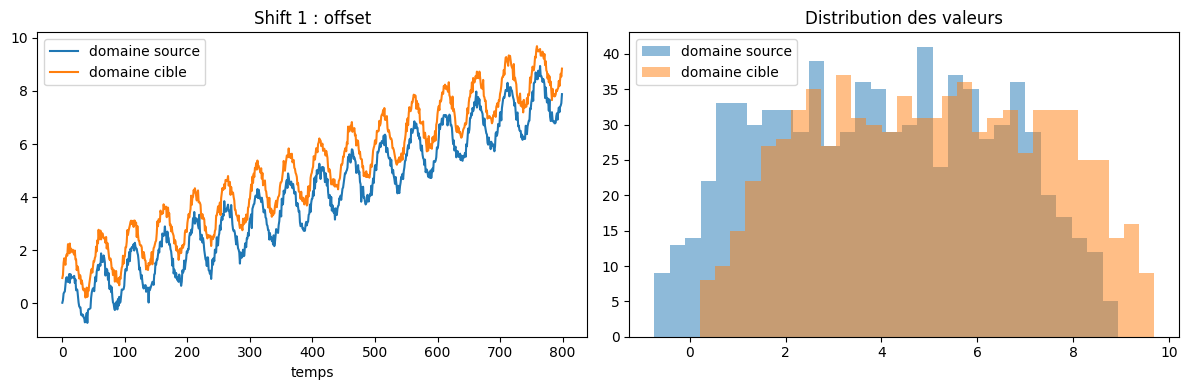

In [6]:
pair_offset = make_domain_pair(source_params, "offset", intensity=1)
plot_domain_pair(pair_offset, "Shift 1 : offset")

## Shift 2 : changement d'echelle

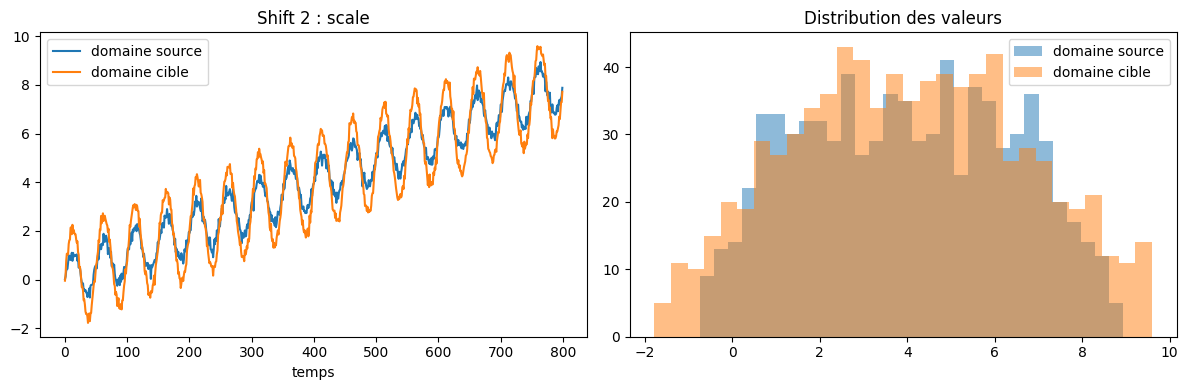

In [7]:
pair_scale = make_domain_pair(source_params, "scale", intensity=1.0)
plot_domain_pair(pair_scale, "Shift 2 : scale")

## Shift 3 : derive de tendance

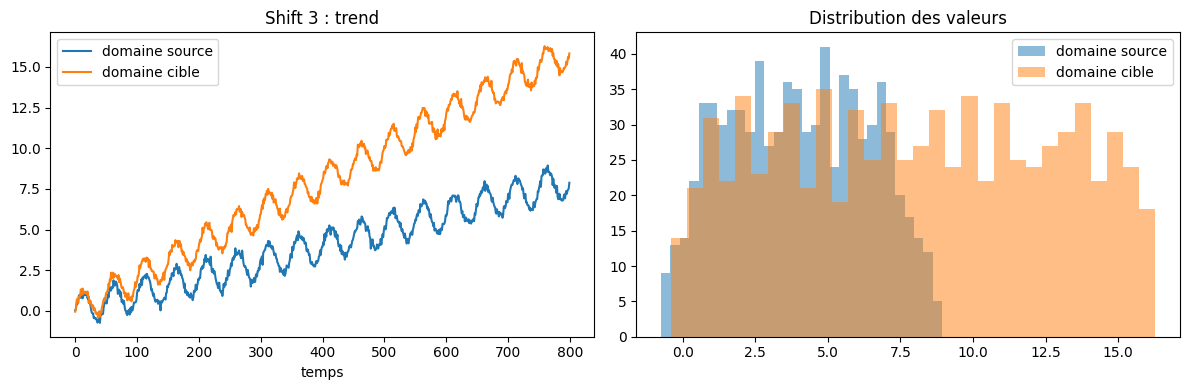

In [8]:
pair_trend = make_domain_pair(source_params, "trend", intensity=1.0)
plot_domain_pair(pair_trend, "Shift 3 : trend")

## Shift 4 : changement de saisonnalite

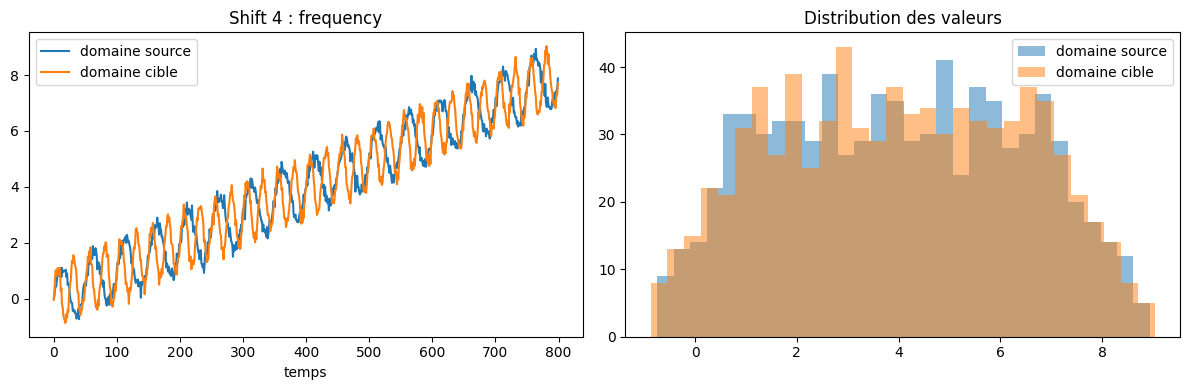

In [9]:
pair_frequency = make_domain_pair(source_params, "frequency", intensity=1.0)
plot_domain_pair(pair_frequency, "Shift 4 : frequency")

## Shift 5 : changement du niveau de bruit

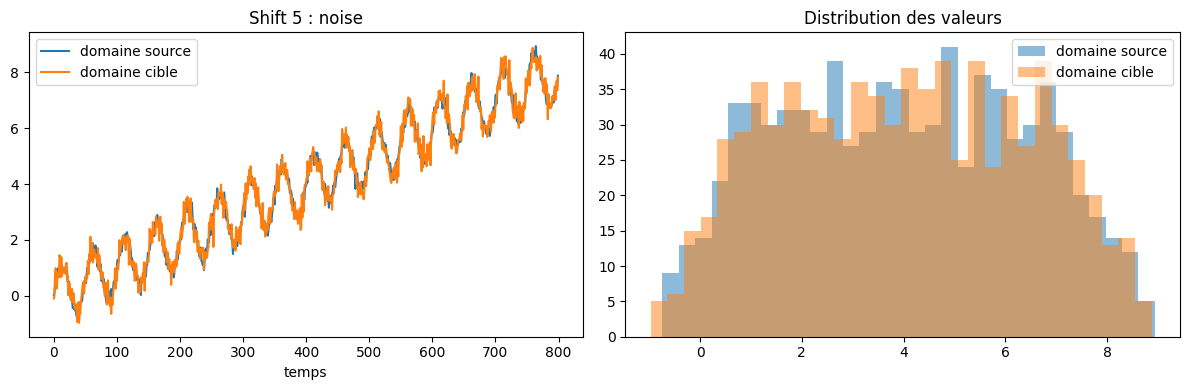

In [10]:
pair_noise = make_domain_pair(source_params, "noise", intensity=1.0)
plot_domain_pair(pair_noise, "Shift 5 : noise")

## Generation pour plusieurs niveaux d'intensite

Génération pour chaque type de shift, plusieurs paires source et cible avec des intensites croissantes.

In [11]:
shift_types = ["offset", "scale", "trend", "frequency", "noise"]
intensity_levels = [0.25, 0.5, 1]

all_pairs = {}
for shift_type in shift_types:
    for intensity in intensity_levels:
        all_pairs[(shift_type, intensity)] = make_domain_pair(source_params, shift_type, intensity)

## Sauvegarde

In [12]:
output_dir = "../data/synthetic"
os.makedirs(output_dir, exist_ok=True)

for (shift_type, intensity), pair in all_pairs.items():
    filename = f"{output_dir}/{shift_type}_intensity_{intensity}.npz"
    np.savez(
        filename,
        Xs=pair["Xs"], ys=pair["ys"],
        Xt=pair["Xt"], yt=pair["yt"],
        series_source=pair["series_source"],
        series_target=pair["series_target"],
    )

## Shift combine : tous les shifts en meme temps

In [13]:
def make_domain_pair_combined(source_params, shift_types, intensity, n_points=800, window_size=20, seed=0):
    rng_source = np.random.default_rng(seed)
    rng_target = np.random.default_rng(seed + 1000)

    target_params = dict(source_params)
    offset = 0.0

    for shift_type in shift_types:
        if shift_type == "offset":
            offset += intensity
        elif shift_type == "scale":
            target_params["seasonal_amplitude"] = target_params["seasonal_amplitude"] * (1 + intensity)
        elif shift_type == "trend":
            target_params["trend_slope"] = target_params["trend_slope"] * (1 + intensity)
        elif shift_type == "frequency":
            target_params["seasonal_period"] = target_params["seasonal_period"] / (1 + intensity)
        elif shift_type == "noise":
            target_params["noise_std"] = target_params["noise_std"] * (1 + intensity)
        else:
            raise ValueError(f"type de shift inconnu : {shift_type}")

    t_source, series_source = generate_series(n_points, rng=rng_source, **source_params)
    t_target, series_target = generate_series(n_points, rng=rng_target, **target_params)
    series_target = series_target + offset

    Xs, ys = sliding_window(series_source, window_size)
    Xt, yt = sliding_window(series_target, window_size)

    return dict(
        t_source=t_source, series_source=series_source, Xs=Xs, ys=ys,
        t_target=t_target, series_target=series_target, Xt=Xt, yt=yt,
        shift_types=shift_types, intensity=intensity,
    )


shift_types_combined = ["offset", "scale", "trend", "frequency", "noise"]

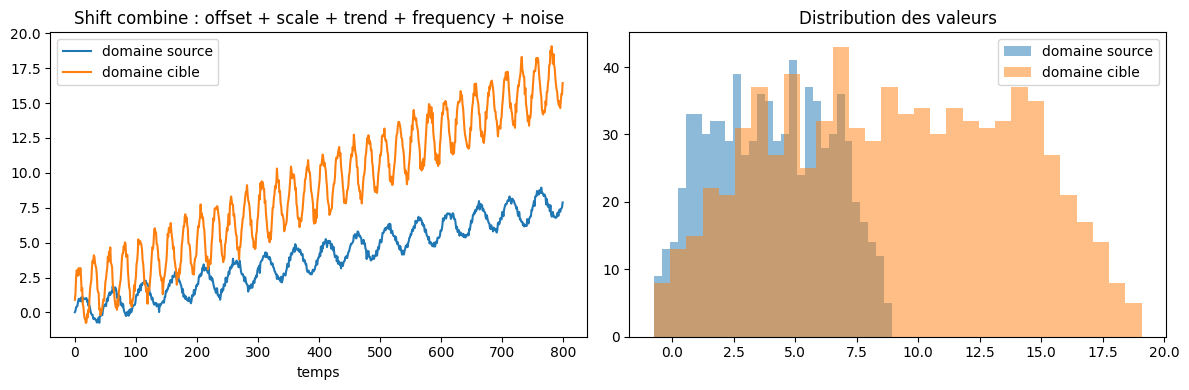

In [14]:
pair_combined = make_domain_pair_combined(source_params, shift_types_combined, intensity=1.0)
plot_domain_pair(pair_combined, "Shift combine : offset + scale + trend + frequency + noise")

## Generation et sauvegarde pour plusieurs niveaux d'intensite (shift combine)

In [15]:
all_pairs_combined = {}
for intensity in intensity_levels:
    all_pairs_combined[intensity] = make_domain_pair_combined(source_params, shift_types_combined, intensity)

for intensity, pair in all_pairs_combined.items():
    filename = f"{output_dir}/combined_intensity_{intensity}.npz"
    np.savez(
        filename,
        Xs=pair["Xs"], ys=pair["ys"],
        Xt=pair["Xt"], yt=pair["yt"],
        series_source=pair["series_source"],
        series_target=pair["series_target"],
    )

## Comparaison avec statsmodels

meme estimation AR(p) que sliding_window + LinearRegression, mais avec AutoReg de statsmodels, pour verifier que les deux approches donnent le meme resultat

In [16]:
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.ar_model import AutoReg

series = pair_offset["series_source"]
Xs, ys = pair_offset["Xs"], pair_offset["ys"]
window_size = Xs.shape[1]

model_manuel = LinearRegression()
model_manuel.fit(Xs, ys)

model_statsmodels = AutoReg(series, lags=window_size, old_names=False).fit()

print("coefficients manuels ", model_manuel.coef_)
print("intercept manuel :", model_manuel.intercept_)
print()
print("coefficients statsmodels", model_statsmodels.params[1:])
print("intercept statsmodels :", model_statsmodels.params[0])

coefficients manuels  [ 0.12644123  0.05834317  0.02123976  0.0369148  -0.02398816  0.02993192
 -0.09703835 -0.07654179 -0.08842469 -0.17353712 -0.06640087 -0.13129803
 -0.03076051  0.0846353   0.08645227  0.0911677   0.20700205  0.25788347
  0.30143859  0.38469028]
intercept manuel : 0.020937552590795327

coefficients statsmodels [ 0.38469028  0.30143859  0.25788347  0.20700205  0.0911677   0.08645227
  0.0846353  -0.03076051 -0.13129803 -0.06640087 -0.17353712 -0.08842469
 -0.07654179 -0.09703835  0.02993192 -0.02398816  0.0369148   0.02123976
  0.05834317  0.12644123]
intercept statsmodels : 0.0209375525908011


manuel : les coefs vont de x[n-p] a x[n-1]

 avec statsmodel, les coefs vont de x[n-1] a x[n-p]

difference max entre les deux estimations

In [17]:
print(np.max(np.abs(model_manuel.coef_[::-1] - model_statsmodels.params[1:])))

2.0192181260370035e-15


## Verification : multiplier le bruit ne change pas les coefficients


In [18]:
from statsmodels.tsa.ar_model import AutoReg
import pandas as pd
import sys
sys.path.insert(0, ".")
from series_utils import generate_series_ar

phi_vrai, sigma_base, n = 0.9, 0.15, 20000

lignes_bruit = []
for facteur in [1, 100]:
    rng = np.random.default_rng(0)
    _, serie = generate_series_ar(n, phi=phi_vrai, trend_slope=0.0, seasonal_amplitude=0.0,
                                  noise_std=sigma_base * facteur, rng=rng)
    res = AutoReg(serie, lags=1, old_names=False).fit()
    lignes_bruit.append([facteur, round(float(res.params[1]), 4), round(float(res.sigma2), 4)])

tab = pd.DataFrame(lignes_bruit, columns=["facteur sur sigma", "phi_1 estime", "variance estimee"])
print(tab.to_string(index=False))
print()
print("rapport des variances estimees :", round(lignes_bruit[1][2] / lignes_bruit[0][2], 1))

 facteur sur sigma  phi_1 estime  variance estimee
                 1        0.9035            0.0223
               100        0.9035          223.2166

rapport des variances estimees : 10009.7
